# 01 – Data Audit: Texas Air Quality (EPA, 2020–2024)

**Project:** Analyzing Air Quality Patterns Across Texas (CSE 4334 Data Mining)

Before we start the research questions, we want to make sure the data is correct. This notebook **only looks at the data**, it does not change or delete anything.

What we check:
1. Which years and pollutants we have
2. Column names, data types and units
3. Missing values, duplicates and strange records
4. Whether the previous filtering/merging was done correctly
5. How many rows each file has and how many were removed before
6. How monitoring-station coverage changes between years
7. Whether anything important was lost during the previous cleaning

**Data source:** EPA AirData daily summary files – https://aqs.epa.gov/aqsweb/airdata/download_files.html
- PM2.5 (parameter code **88101**)
- Ozone (parameter code **44201**)

## 0. Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# the notebook lives in notebooks/, the data folders are one level up
DATA = ".."
YEARS = [2020, 2021, 2022, 2023, 2024]

**Important note about loading the CSVs:** EPA uses the text `None` in the `event_type` column to mean "no special event".
By default pandas turns the word `None` into a missing value (NaN), which makes it look like 99% of `event_type` is missing.
So we always read the files with `keep_default_na=False, na_values=[""]` – only truly empty cells become NaN.

In [2]:
# quick demo of the problem
demo_default = pd.read_csv(f"{DATA}/Texas_Filtered_Data/Texas_Ozone_2020.csv", usecols=["event_type"])
demo_fixed = pd.read_csv(f"{DATA}/Texas_Filtered_Data/Texas_Ozone_2020.csv", usecols=["event_type"],
                         keep_default_na=False, na_values=[""])
print("Default read  -> missing event_type:", demo_default["event_type"].isna().sum())
print("Correct read  -> missing event_type:", demo_fixed["event_type"].isna().sum())
print(demo_fixed["event_type"].value_counts())

Default read  -> missing event_type: 25734
Correct read  -> missing event_type: 0
event_type
None        25734
Included      135
Excluded        4
Name: count, dtype: int64


## 1. What files do we have?

In [3]:
rows = []
for folder in ["Original_Datasets", "Texas_Filtered_Data", "Combined_Datasets"]:
    for f in sorted(os.listdir(f"{DATA}/{folder}")):
        size_mb = os.path.getsize(f"{DATA}/{folder}/{f}") / 1e6
        rows.append({"folder": folder, "file": f, "size_MB": round(size_mb, 1)})

files = pd.DataFrame(rows)
files

,folder,file,size_MB
0,Original_Datasets,daily_44201_2020.zip,4.7
1,Original_Datasets,daily_44201_2021.zip,4.7
2,Original_Datasets,daily_44201_2022.zip,4.6
3,Original_Datasets,daily_44201_2023.zip,4.7
4,Original_Datasets,daily_44201_2024.zip,4.6
5,Original_Datasets,daily_88101_2020.zip,7.9
6,Original_Datasets,daily_88101_2021.zip,9.0
7,Original_Datasets,daily_88101_2022.zip,9.7
8,Original_Datasets,daily_88101_2023.zip,9.9
9,Original_Datasets,daily_88101_2024.zip,8.4


- **Original_Datasets**: the 10 national EPA ZIP files (5 years × 2 pollutants), never modified.
- **Texas_Filtered_Data**: one CSV per pollutant per year, Texas only.
- **Combined_Datasets**: the yearly files stacked into one file per pollutant, plus a PM2.5 + ozone merged file.

## 2. Original EPA files – how many rows, and how many are Texas?

We read only the `State Code` column from each ZIP (much faster than loading everything). Texas is state code `48`.
We also check that all 10 ZIPs have the same column names.

In [4]:
pollutant_codes = {"PM25": "88101", "Ozone": "44201"}

raw_rows = []
headers = {}
for pollutant, code in pollutant_codes.items():
    for year in YEARS:
        path = f"{DATA}/Original_Datasets/daily_{code}_{year}.zip"
        headers[(pollutant, year)] = list(pd.read_csv(path, nrows=0).columns)
        states = pd.read_csv(path, usecols=["State Code"], dtype=str)
        raw_rows.append({"pollutant": pollutant, "year": year,
                         "all_US_rows": len(states),
                         "texas_rows": (states["State Code"] == "48").sum()})

raw_counts = pd.DataFrame(raw_rows)
raw_counts["texas_percent"] = (100 * raw_counts["texas_rows"] / raw_counts["all_US_rows"]).round(1)
raw_counts

,pollutant,year,all_US_rows,texas_rows,texas_percent
0,PM25,2020,704092,26383,3.7
1,PM25,2021,790468,29851,3.8
2,PM25,2022,863466,34565,4.0
3,PM25,2023,847162,35405,4.2
4,PM25,2024,740924,38015,5.1
5,Ozone,2020,395536,25873,6.5
6,Ozone,2021,394384,26508,6.7
7,Ozone,2022,387156,25639,6.6
8,Ozone,2023,388607,25659,6.6
9,Ozone,2024,386972,25954,6.7


In [5]:
first_header = headers[("PM25", 2020)]
same = all(h == first_header for h in headers.values())
print("Number of columns in each ZIP:", len(first_header))
print("All 10 ZIP files have identical column names:", same)

Number of columns in each ZIP: 29
All 10 ZIP files have identical column names: True


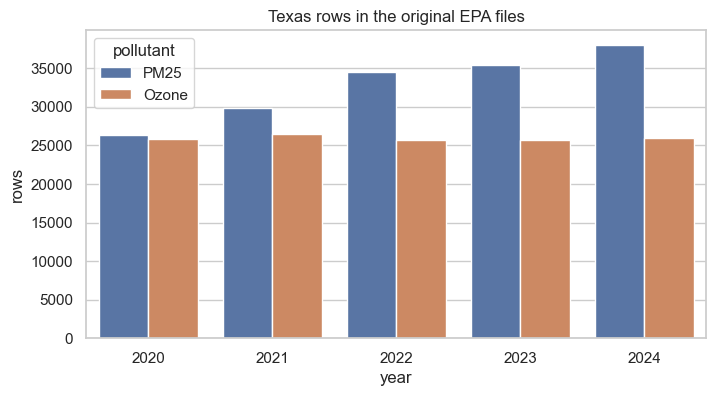

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=raw_counts, x="year", y="texas_rows", hue="pollutant", ax=ax)
ax.set_title("Texas rows in the original EPA files")
ax.set_ylabel("rows")
plt.show()

Both pollutants have Texas data for **all five years**, so there is no missing year.
PM2.5 has more rows than ozone even though it has fewer stations – we will see why in Section 5 (PM2.5 stores each day twice).

## 3. Texas filtered files (one per pollutant per year)

Load all 10 yearly files and compare their shape, columns and data types.

In [7]:
yearly = {}
shape_rows = []
for pollutant in ["PM25", "Ozone"]:
    for year in YEARS:
        df = pd.read_csv(f"{DATA}/Texas_Filtered_Data/Texas_{pollutant}_{year}.csv",
                         keep_default_na=False, na_values=[""], low_memory=False)
        yearly[(pollutant, year)] = df
        shape_rows.append({"pollutant": pollutant, "year": year, "rows": df.shape[0], "columns": df.shape[1]})

shapes = pd.DataFrame(shape_rows)
shapes

,pollutant,year,rows,columns
0,PM25,2020,26383,34
1,PM25,2021,29851,34
2,PM25,2022,34565,34
3,PM25,2023,35405,34
4,PM25,2024,38015,34
5,Ozone,2020,25873,34
6,Ozone,2021,26508,34
7,Ozone,2022,25639,34
8,Ozone,2023,25659,34
9,Ozone,2024,25954,34


In [8]:
# are column names and data types the same in every yearly file?
base_cols = list(yearly[("PM25", 2020)].columns)
print("Same column names in all 10 files:", all(list(d.columns) == base_cols for d in yearly.values()))

dtypes = pd.DataFrame({f"{p} {y}": d.dtypes.astype(str) for (p, y), d in yearly.items()})
# only show columns whose type is NOT the same in every file
dtypes[dtypes.nunique(axis=1) > 1]

Same column names in all 10 files: True


,PM25 2020,PM25 2021,PM25 2022,PM25 2023,PM25 2024,Ozone 2020,Ozone 2021,Ozone 2022,Ozone 2023,Ozone 2024
aqi,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64
method_code,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64
record_note,object,object,object,object,object,object,float64,object,float64,float64


Only 3 columns change type, and none of them is a real problem:
- `aqi` is float for PM2.5 (because `1 HOUR` rows have no AQI) and int for ozone.
- `method_code` is float in Ozone 2021 because one row is missing its method code.
- `record_note` is float in years where it is completely empty.

All measurement columns (`arithmetic_mean`, `first_max_value`, dates, coordinates) have the same type every year.

In [9]:
print("Columns:")
print(base_cols)

Columns:
['site_id', 'year', 'pollutant', 'state_code', 'county_code', 'site_num', 'parameter_code', 'poc', 'latitude', 'longitude', 'datum', 'parameter_name', 'sample_duration', 'pollutant_standard', 'date_local', 'units_of_measure', 'event_type', 'observation_count', 'observation_percent', 'arithmetic_mean', 'first_max_value', 'first_max_hour', 'aqi', 'method_code', 'method_name', 'local_site_name', 'address', 'state_name', 'county_name', 'city_name', 'cbsa_name', 'date_of_last_change', 'analysis_record', 'record_note']


### 3.1 Did the previous filtering lose any Texas rows?

Compare the Texas rows inside the original ZIPs (Section 2) with the rows in the filtered CSVs.

In [10]:
compare = raw_counts.merge(shapes, on=["pollutant", "year"])
compare["rows_removed"] = compare["texas_rows"] - compare["rows"]
compare[["pollutant", "year", "all_US_rows", "texas_rows", "rows", "rows_removed"]]

,pollutant,year,all_US_rows,texas_rows,rows,rows_removed
0,PM25,2020,704092,26383,26383,0
1,PM25,2021,790468,29851,29851,0
2,PM25,2022,863466,34565,34565,0
3,PM25,2023,847162,35405,35405,0
4,PM25,2024,740924,38015,38015,0
5,Ozone,2020,395536,25873,25873,0
6,Ozone,2021,394384,26508,26508,0
7,Ozone,2022,387156,25639,25639,0
8,Ozone,2023,388607,25659,25659,0
9,Ozone,2024,386972,25954,25954,0


In [11]:
# every row really is Texas and has the right pollutant code
for (pollutant, year), df in yearly.items():
    ok_state = (df["state_code"] == 48).all() and (df["state_name"] == "Texas").all()
    ok_code = (df["parameter_code"] == int(pollutant_codes[pollutant])).all()
    ok_year = (df["date_local"].str[:4] == str(year)).all()
    print(pollutant, year, "| all Texas:", ok_state, "| right pollutant:", ok_code, "| dates in year:", ok_year)

PM25 2020 | all Texas: True | right pollutant: True | dates in year: True
PM25 2021 | all Texas: True | right pollutant: True | dates in year: True
PM25 2022 | all Texas: True | right pollutant: True | dates in year: True
PM25 2023 | all Texas: True | right pollutant: True | dates in year: True
PM25 2024 | all Texas: True | right pollutant: True | dates in year: True
Ozone 2020 | all Texas: True | right pollutant: True | dates in year: True
Ozone 2021 | all Texas: True | right pollutant: True | dates in year: True
Ozone 2022 | all Texas: True | right pollutant: True | dates in year: True
Ozone 2023 | all Texas: True | right pollutant: True | dates in year: True
Ozone 2024 | all Texas: True | right pollutant: True | dates in year: True


**Result:** no rows were removed during filtering – every Texas row from EPA is in the filtered files.
Instead of deleting records, the previous script added two columns:
- `analysis_record` (TRUE/FALSE) – whether the row should be used for analysis
- `record_note` – the reason a row is marked FALSE (or a comment)

We check whether those flags make sense in Section 5.

## 4. Units, sample durations and measurement methods
Mixing different units would make the numbers meaningless, so we check them per year.

In [12]:
pm = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_PM25_Combined.csv",
                 keep_default_na=False, na_values=[""], low_memory=False)
oz = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_Ozone_Combined.csv",
                 keep_default_na=False, na_values=[""], low_memory=False)

print("PM2.5 units:", pm["units_of_measure"].unique())
print("Ozone units:", oz["units_of_measure"].unique())
print()
print("PM2.5 datum:", pm["datum"].value_counts().to_dict())
print("Ozone datum:", oz["datum"].value_counts().to_dict())

PM2.5 units: ['Micrograms/cubic meter (LC)']
Ozone units: ['Parts per million']

PM2.5 datum: {'WGS84': 164219}
Ozone datum: {'WGS84': 129259, 'NAD83': 374}


In [13]:
pd.crosstab(pm["sample_duration"], pm["year"], margins=True)

year,2020,2021,2022,2023,2024,All
sample_duration,,,,,,
1 HOUR,12642,14474,17003,17437,18800,80356
24 HOUR,1446,1278,982,910,906,5522
24-HR BLK AVG,12295,14099,16580,17058,18309,78341
All,26383,29851,34565,35405,38015,164219


In [14]:
pd.crosstab(oz["sample_duration"], oz["year"], margins=True)

year,2020,2021,2022,2023,2024,All
sample_duration,,,,,,
8-HR RUN AVG BEGIN HOUR,25873,26508,25639,25659,25954,129633
All,25873,26508,25639,25659,25954,129633


In [15]:
# PM2.5 measurement methods (only rows used for analysis)
pm_used = pm[pm["analysis_record"]]
pd.crosstab([pm_used["method_code"], pm_used["method_name"].str[:60]], pm_used["year"])

,year,2020,2021,2022,2023,2024
method_code,method_name,,,,,
145,R & P Model 2025 PM-2.5 Sequential Air Sampler w/VSCC - Grav,1446,1278,982,910,906
170,Met One BAM-1020 Mass Monitor w/VSCC - Beta Attenuation,1012,1021,965,426,0
209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM2.5C - Beta At,11283,13078,15615,15703,15509
238,Teledyne T640X at 16.67 LPM - Broadband spectroscopy,0,0,0,111,0
638,Teledyne T640X at 16.67 LPM w/Network Data Alignment enabled,0,0,0,707,2800
738,Teledyne T640X at 16.67 LPM (Corrected) - Broadband spectros,0,0,0,111,0


In [16]:
pd.crosstab([oz["method_code"].fillna(-1), oz["method_name"].str[:60]], oz["year"])

,year,2020,2021,2022,2023,2024
method_code,method_name,,,,,
-1.0,-,0,1,0,0,0
47.0,INSTRUMENTAL - ULTRA VIOLET,4279,4623,4640,4671,4172
87.0,INSTRUMENTAL - ULTRA VIOLET ABSORPTION,21464,21731,20908,20988,21782
190.0,Instrumental - UV absorption photometry/UV 2B model 202 and,130,153,91,0,0


- **Units are consistent**: PM2.5 is always µg/m³ and ozone is always ppm, in every year.
- PM2.5 is measured by several instruments (lab filters "FRM" and continuous "BAM/T640" monitors). All of them are EPA-approved for parameter 88101, so they can be compared.
- Ozone uses one daily value type: the 8-hour running average (`first_max_value` = the daily max 8-hour average, which is what the ozone standard and AQI use).
- **Datum**: 374 ozone rows use NAD83 coordinates instead of WGS84. The difference is about 1 meter, so this does not matter for maps.
- One ozone row has a missing `method_code` (shown as -1 above).

## 5. Record types – does the `analysis_record` flag make sense?

### 5.1 PM2.5: "1 HOUR" vs "24-HR BLK AVG" rows
Continuous PM2.5 monitors appear **twice** per day in the EPA file:
- `1 HOUR` – a daily summary of the hourly readings (no AQI, no standard)
- `24-HR BLK AVG` – the official daily average (has AQI). EPA only creates it when at least 18 of 24 hours (75%) were measured.

If we used both we would count the same day twice. Let's confirm they are really the same measurement.

In [17]:
key = ["site_id", "poc", "date_local"]
hourly = pm[pm["sample_duration"] == "1 HOUR"][key + ["arithmetic_mean", "observation_count"]]
daily = pm[pm["sample_duration"] == "24-HR BLK AVG"][key + ["arithmetic_mean"]]

pairs = hourly.merge(daily, on=key, how="left", suffixes=("_1hour", "_24hr"), indicator=True)
pairs["_merge"].value_counts()

_merge
both          78341
left_only      2015
right_only        0
Name: count, dtype: int64

In [18]:
both = pairs[pairs["_merge"] == "both"]
diff = (both["arithmetic_mean_1hour"] - both["arithmetic_mean_24hr"]).abs()
print("Monitor-days that have BOTH rows:", len(both))
print("Largest difference between the two daily means:", round(diff.max(), 3), "µg/m³")

only_hourly = pairs[pairs["_merge"] == "left_only"]
print()
print("Monitor-days that ONLY have a '1 HOUR' row:", len(only_hourly))
print("Hours measured on those days:")
print(only_hourly["observation_count"].describe()[["min", "max", "mean"]])

Monitor-days that have BOTH rows: 78341
Largest difference between the two daily means: 0.096 µg/m³

Monitor-days that ONLY have a '1 HOUR' row: 2015
Hours measured on those days:
min      1.000000
max     17.000000
mean    11.483871
Name: observation_count, dtype: float64


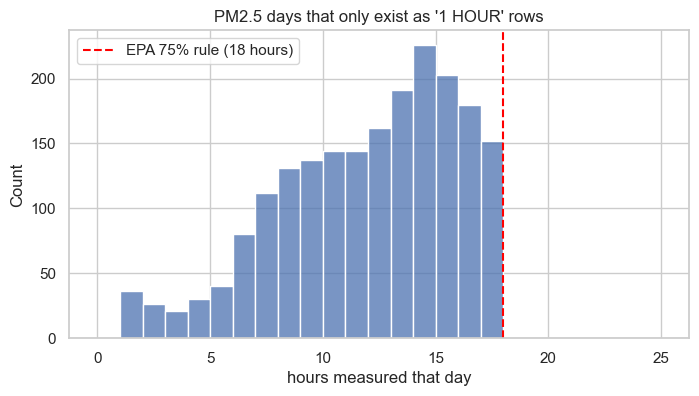

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(only_hourly["observation_count"], bins=range(0, 26), ax=ax)
ax.axvline(18, color="red", linestyle="--", label="EPA 75% rule (18 hours)")
ax.set_title("PM2.5 days that only exist as '1 HOUR' rows")
ax.set_xlabel("hours measured that day")
ax.legend()
plt.show()

- When both rows exist, the means differ by less than 0.1 µg/m³ (just rounding) → the `1 HOUR` row is a true duplicate of the same measurement. Flagging it as `analysis_record = FALSE` is **correct**.
- 2,015 monitor-days only have a `1 HOUR` row because the monitor ran for fewer than 18 hours. EPA does not consider these complete days, so leaving them out of analysis is also **reasonable** – they are still in the file if we ever need them.

### 5.2 Ozone: "Excluded" vs "Included" event rows
When a day is affected by an exceptional event (like a wildfire), EPA can publish two versions of the same monitor-day: one with the event hours **Included** and one with them **Excluded**.

In [20]:
print(oz["event_type"].value_counts())
key = ["site_id", "poc", "date_local", "sample_duration"]
dup_days = oz[oz.duplicated(key, keep=False)].sort_values(key)
print("\nMonitor-days with two versions:", dup_days[key].drop_duplicates().shape[0])
dup_days[["site_id", "date_local", "event_type", "first_max_value", "aqi", "analysis_record"]].head(6)

event_type
None        129226
Included       391
Excluded        16
Name: count, dtype: int64

Monitor-days with two versions: 16


,site_id,date_local,event_type,first_max_value,aqi,analysis_record
63388,48-201-0055,2022-06-19,Included,0.057,58,True
63389,48-201-0055,2022-06-19,Excluded,0.057,58,False
63390,48-201-0055,2022-06-20,Excluded,0.042,140,False
63391,48-201-0055,2022-06-20,Included,0.082,140,True
63463,48-201-0055,2022-09-12,Excluded,0.066,87,False
63464,48-201-0055,2022-09-12,Included,0.066,87,True


The previous cleaning kept the **Included** version (the actual measured air) and flagged the **Excluded** one as FALSE. That's the right choice for describing what people actually breathed.

In [21]:
# summary of what is used vs. flagged
summary = pd.DataFrame({
    "pollutant": ["PM2.5", "Ozone"],
    "total_rows": [len(pm), len(oz)],
    "analysis_rows (TRUE)": [pm["analysis_record"].sum(), oz["analysis_record"].sum()],
    "flagged_rows (FALSE)": [(~pm["analysis_record"]).sum(), (~oz["analysis_record"]).sum()],
})
summary

,pollutant,total_rows,analysis_rows (TRUE),flagged_rows (FALSE)
0,PM2.5,164219,83863,80356
1,Ozone,129633,129617,16


## 6. Missing values
We count missing values in every column, first for all rows and then only for the analysis rows.

In [22]:
missing = pd.DataFrame({
    "PM25_missing": pm.isna().sum(),
    "PM25_%": (100 * pm.isna().mean()).round(2),
    "Ozone_missing": oz.isna().sum(),
    "Ozone_%": (100 * oz.isna().mean()).round(2),
})
missing[(missing["PM25_missing"] > 0) | (missing["Ozone_missing"] > 0)]

,PM25_missing,PM25_%,Ozone_missing,Ozone_%
pollutant_standard,80356,48.93,0,0.00
aqi,80356,48.93,0,0.00
method_code,0,0.00,1,0.00
local_site_name,3469,2.11,0,0.00
cbsa_name,3240,1.97,3849,2.97
record_note,83775,51.01,129617,99.99


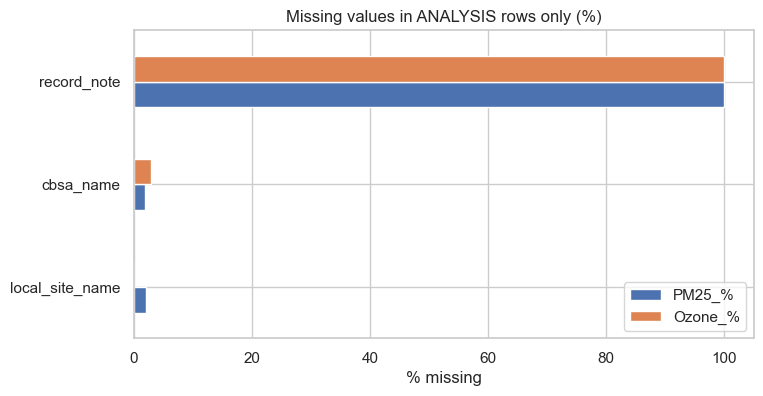

,PM25_%,Ozone_%
local_site_name,2.04,0.00
cbsa_name,1.89,2.97
record_note,99.90,100.00


In [23]:
pm_used = pm[pm["analysis_record"]]
oz_used = oz[oz["analysis_record"]]

missing_used = pd.DataFrame({
    "PM25_%": (100 * pm_used.isna().mean()).round(2),
    "Ozone_%": (100 * oz_used.isna().mean()).round(2),
})
missing_used = missing_used[(missing_used["PM25_%"] > 0) | (missing_used["Ozone_%"] > 0)]

missing_used.plot(kind="barh", figsize=(8, 4))
plt.title("Missing values in ANALYSIS rows only (%)")
plt.xlabel("% missing")
plt.show()
missing_used

In [24]:
# which sites/counties cause the missing names?
print("PM2.5 sites with no local_site_name:", pm_used[pm_used["local_site_name"].isna()]["site_id"].unique())
print("Counties with no CBSA (metro area):",
      sorted(set(pm_used[pm_used["cbsa_name"].isna()]["county_name"]) | set(oz_used[oz_used["cbsa_name"].isna()]["county_name"])))

PM2.5 sites with no local_site_name: ['48-361-1100']
Counties with no CBSA (metro area): ['Brewster', 'Culberson', 'Polk']


- **The measurement columns (`arithmetic_mean`, `first_max_value`, `aqi`, `date_local`, `latitude`, `longitude`) have no missing values in the analysis rows.**
- The big gaps in the full PM2.5 file (`pollutant_standard`, `aqi`, ~49%) come only from the flagged `1 HOUR` rows, which EPA never gives an AQI.
- `local_site_name` is missing for one PM2.5 site (48-361-1100, Orange County). We can label it by its site ID or city.
- `cbsa_name` (metro area) is missing for rural counties that are not part of any metro area (Brewster, Culberson, Polk). This is normal, not an error.
- `record_note` is empty on purpose for normal rows.

**Nothing needs to be filled in.**

## 7. Duplicates

In [25]:
key = ["site_id", "poc", "date_local", "sample_duration", "event_type"]
dup_table = pd.DataFrame({
    "pollutant": ["PM2.5", "Ozone"],
    "exact_duplicate_rows": [pm.duplicated().sum(), oz.duplicated().sum()],
    "duplicate_monitor_days (site+poc+date+duration+event)": [pm.duplicated(key).sum(), oz.duplicated(key).sum()],
})
dup_table

,pollutant,exact_duplicate_rows,duplicate_monitor_days (site+poc+date+duration+event)
0,PM2.5,0,0
1,Ozone,0,0


There are **no duplicate rows**. But one thing is important for later analysis: some PM2.5 sites have **more than one monitor** (different `poc` numbers) measuring on the same day.

In [26]:
pm_site_day = pm_used.groupby(["site_id", "date_local"]).size()
print("PM2.5 analysis rows:", len(pm_used))
print("Unique PM2.5 site-days:", len(pm_site_day))
print("Site-days with more than one monitor:", (pm_site_day > 1).sum())

oz_site_day = oz_used.groupby(["site_id", "date_local"]).size()
print("\nOzone site-days with more than one monitor:", (oz_site_day > 1).sum())

PM2.5 analysis rows: 83863
Unique PM2.5 site-days: 76660
Site-days with more than one monitor: 7047

Ozone site-days with more than one monitor: 0


In [27]:
# example: one site, one day, two monitors
example = pm_site_day[pm_site_day > 1].index[0]
pm_used[(pm_used["site_id"] == example[0]) & (pm_used["date_local"] == example[1])][
    ["site_id", "date_local", "poc", "sample_duration", "method_name", "arithmetic_mean"]]

,site_id,date_local,poc,sample_duration,method_name,arithmetic_mean
1142,48-029-0032,2020-01-04,1,24 HOUR,R & P Model 2025 PM-2.5 Sequential Air Sampler...,5.2
1180,48-029-0032,2020-01-04,2,24-HR BLK AVG,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,5.6


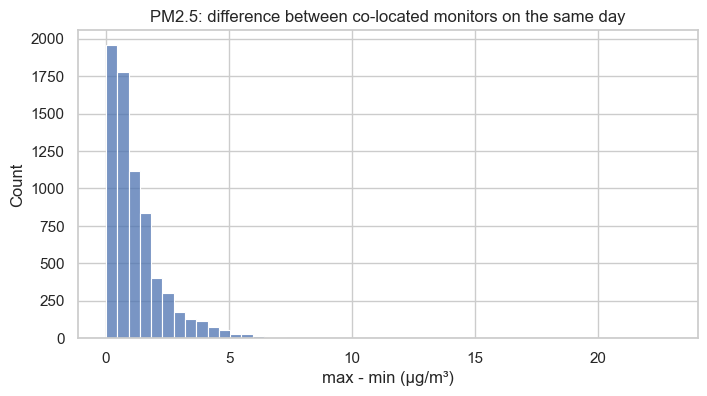

count    7047.00
mean        1.21
std         1.23
min         0.00
25%         0.40
50%         0.90
75%         1.60
max        22.90
Name: arithmetic_mean, dtype: float64


In [28]:
# how close are two monitors at the same site on the same day?
multi = pm_used[pm_used.duplicated(["site_id", "date_local"], keep=False)]
spread = multi.groupby(["site_id", "date_local"])["arithmetic_mean"].agg(lambda x: x.max() - x.min())

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(spread, bins=50, ax=ax)
ax.set_title("PM2.5: difference between co-located monitors on the same day")
ax.set_xlabel("max - min (µg/m³)")
plt.show()
print(spread.describe().round(2))

These are **not duplicates** – they are two real instruments at the same location. If we simply count rows, these sites would get extra weight.
For site-level analysis we should average them into **one value per site per day** (the merged file already does this).

## 8. Comparing years

In [29]:
yearly_summary = pd.DataFrame({
    "PM25_rows_used": pm_used.groupby("year").size(),
    "PM25_sites": pm_used.groupby("year")["site_id"].nunique(),
    "PM25_counties": pm_used.groupby("year")["county_name"].nunique(),
    "Ozone_rows_used": oz_used.groupby("year").size(),
    "Ozone_sites": oz_used.groupby("year")["site_id"].nunique(),
    "Ozone_counties": oz_used.groupby("year")["county_name"].nunique(),
})
yearly_summary

,PM25_rows_used,PM25_sites,PM25_counties,Ozone_rows_used,Ozone_sites,Ozone_counties
year,,,,,,
2020,13741,43,26,25869,74,35
2021,15377,47,27,26508,76,35
2022,17562,49,29,25627,75,35
2023,17968,51,29,25659,73,34
2024,19215,54,29,25954,73,34


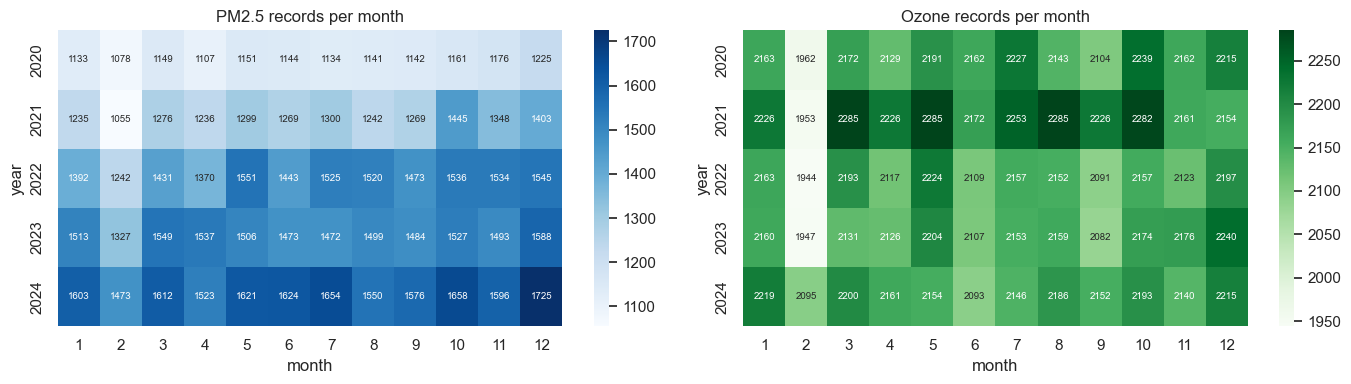

In [30]:
pm_used = pm_used.copy()
oz_used = oz_used.copy()
pm_used["month"] = pd.to_datetime(pm_used["date_local"]).dt.month
oz_used["month"] = pd.to_datetime(oz_used["date_local"]).dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(pd.crosstab(pm_used["year"], pm_used["month"]), cmap="Blues", annot=True, fmt="d",
            annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("PM2.5 records per month")
sns.heatmap(pd.crosstab(oz_used["year"], oz_used["month"]), cmap="Greens", annot=True, fmt="d",
            annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Ozone records per month")
plt.tight_layout()
plt.show()

- Every month of every year has data for both pollutants – no month is missing, which is good news for the **seasonal** part of Research Question 1.
- PM2.5 records grow each year (more monitors were added), while ozone stays about the same.

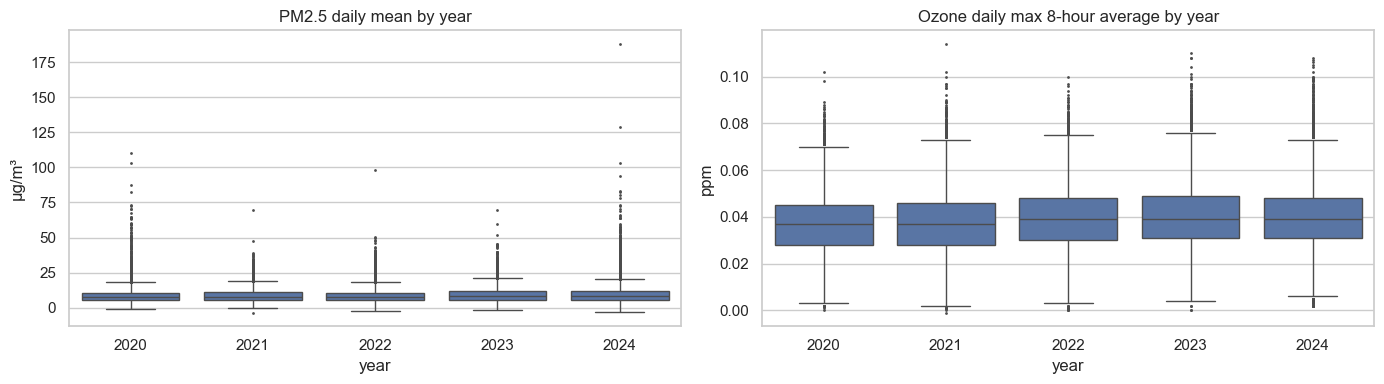

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=pm_used, x="year", y="arithmetic_mean", ax=axes[0], fliersize=1)
axes[0].set_title("PM2.5 daily mean by year")
axes[0].set_ylabel("µg/m³")
sns.boxplot(data=oz_used, x="year", y="first_max_value", ax=axes[1], fliersize=1)
axes[1].set_title("Ozone daily max 8-hour average by year")
axes[1].set_ylabel("ppm")
plt.tight_layout()
plt.show()

## 9. Monitoring-station coverage across years
A site that only measured for a few months can bias averages, so we look at how many days each site has per year.

In [32]:
days_in_year = {2020: 366, 2021: 365, 2022: 365, 2023: 365, 2024: 366}

pm_cov = pm_used.groupby(["site_id", "year"])["date_local"].nunique().unstack()
oz_cov = oz_used.groupby(["site_id", "year"])["date_local"].nunique().unstack()
for y in YEARS:
    pm_cov[y] = (100 * pm_cov[y] / days_in_year[y]).round(1)
    oz_cov[y] = (100 * oz_cov[y] / days_in_year[y]).round(1)

print("PM2.5 sites:", len(pm_cov), "| Ozone sites:", len(oz_cov))
print("\nNumber of years each PM2.5 site has data:")
print(pm_cov.notna().sum(axis=1).value_counts().sort_index())
print("\nNumber of years each ozone site has data:")
print(oz_cov.notna().sum(axis=1).value_counts().sort_index())

PM2.5 sites: 57 | Ozone sites: 76

Number of years each PM2.5 site has data:
1     4
2     4
3     4
4     5
5    40
Name: count, dtype: int64

Number of years each ozone site has data:
2     1
3     2
4     2
5    71
Name: count, dtype: int64


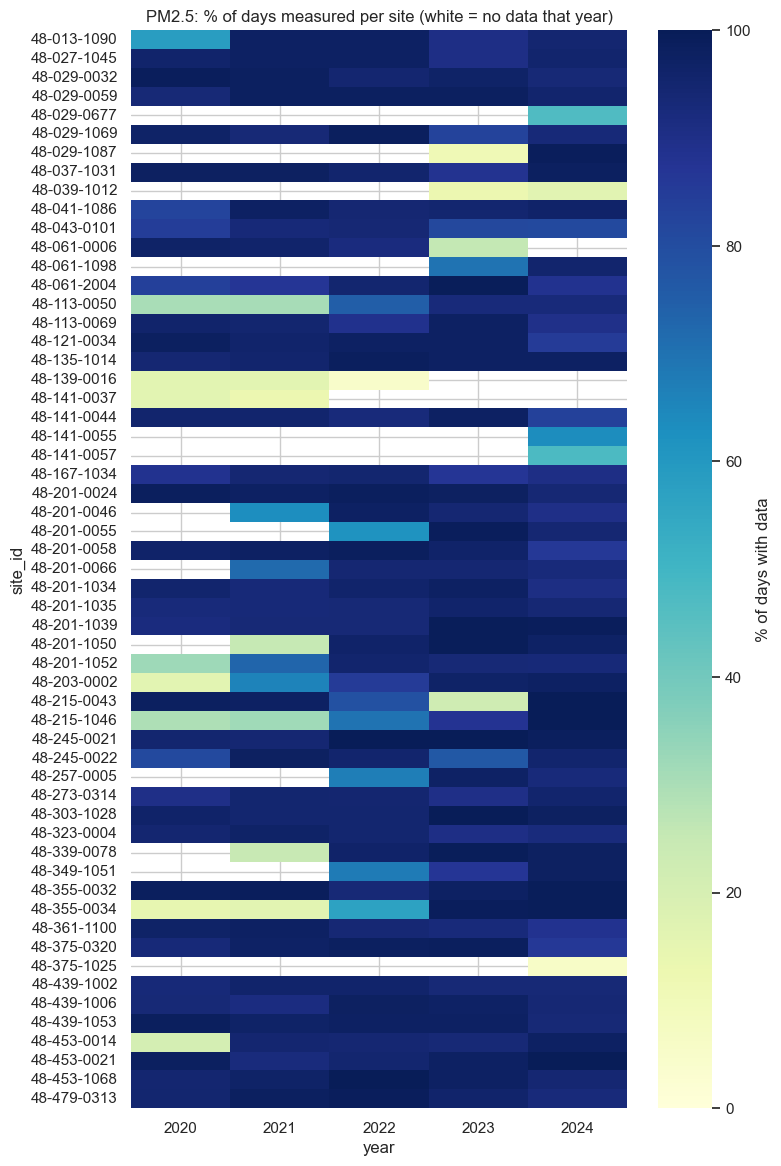

In [33]:
fig, ax = plt.subplots(figsize=(8, 14))
sns.heatmap(pm_cov, cmap="YlGnBu", vmin=0, vmax=100, cbar_kws={"label": "% of days with data"}, ax=ax)
ax.set_title("PM2.5: % of days measured per site (white = no data that year)")
plt.show()

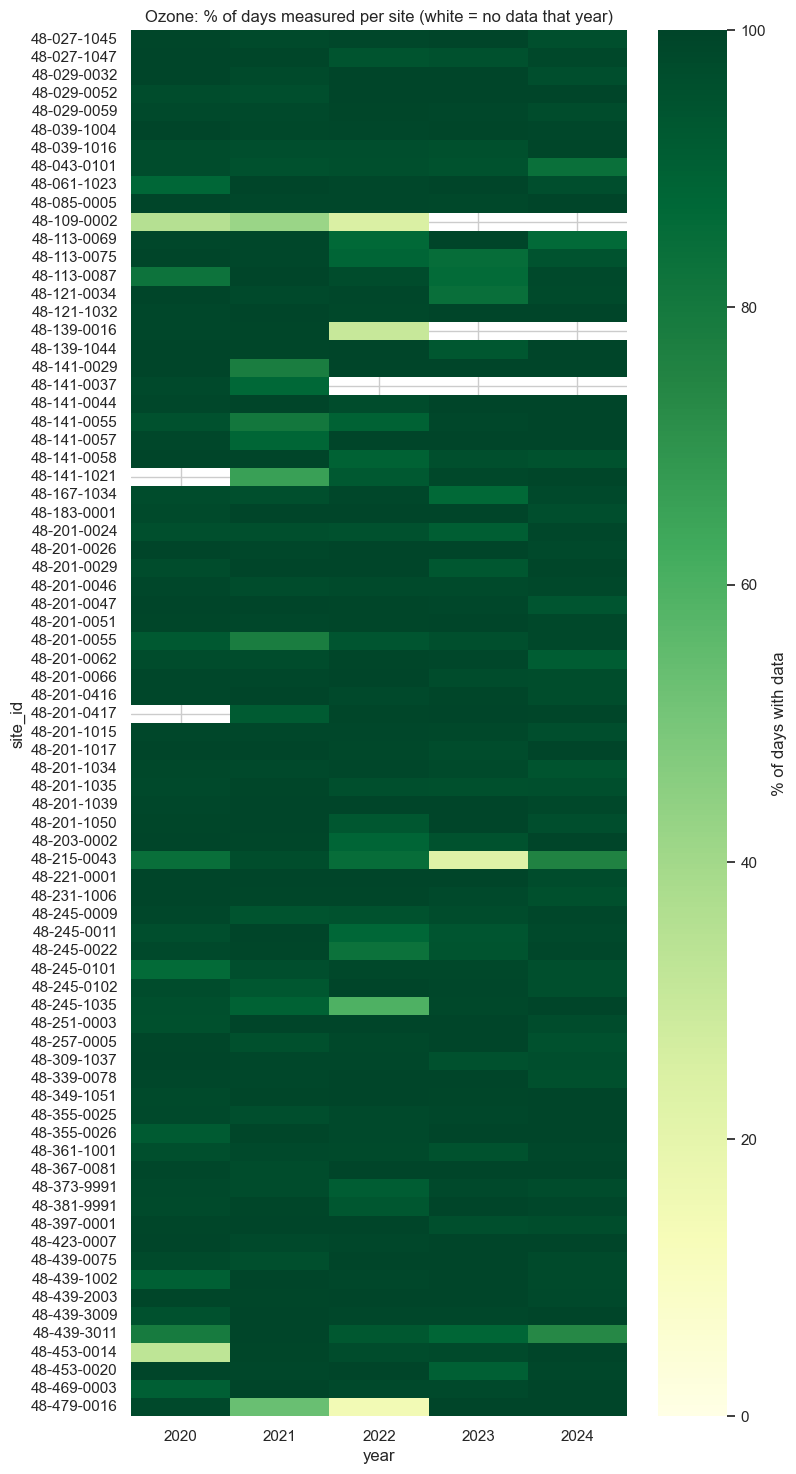

In [34]:
fig, ax = plt.subplots(figsize=(8, 18))
sns.heatmap(oz_cov, cmap="YlGn", vmin=0, vmax=100, cbar_kws={"label": "% of days with data"}, ax=ax)
ax.set_title("Ozone: % of days measured per site (white = no data that year)")
plt.show()

In [35]:
# sites that started or stopped during 2020-2024
for name, cov in [("PM2.5", pm_cov), ("Ozone", oz_cov)]:
    first_year = cov.notna().idxmax(axis=1)
    last_year = cov.notna()[cov.columns[::-1]].idxmax(axis=1)
    print(name, "sites that started after 2020:", (first_year > 2020).sum(),
          "| sites that stopped before 2024:", (last_year < 2024).sum())

PM2.5 sites that started after 2020: 14 | sites that stopped before 2024: 3
Ozone sites that started after 2020: 2 | sites that stopped before 2024: 3


In [36]:
# low-coverage site-years (less than 50% of days)
low_pm = pm_cov.stack()
low_oz = oz_cov.stack()
print("PM2.5 site-years with < 50% of days:", (low_pm < 50).sum(), "of", len(low_pm))
print("Ozone site-years with < 50% of days:", (low_oz < 50).sum(), "of", len(low_oz))

PM2.5 site-years with < 50% of days: 24 of 244
Ozone site-years with < 50% of days: 7 of 371


Of the 24 PM2.5 site-years under 50%, 15 are **filter-based (FRM) monitors that only sample every 3rd or 6th day** by design – that is normal, not a data problem.
The other 9 are sites that started in the middle of a year or closed.

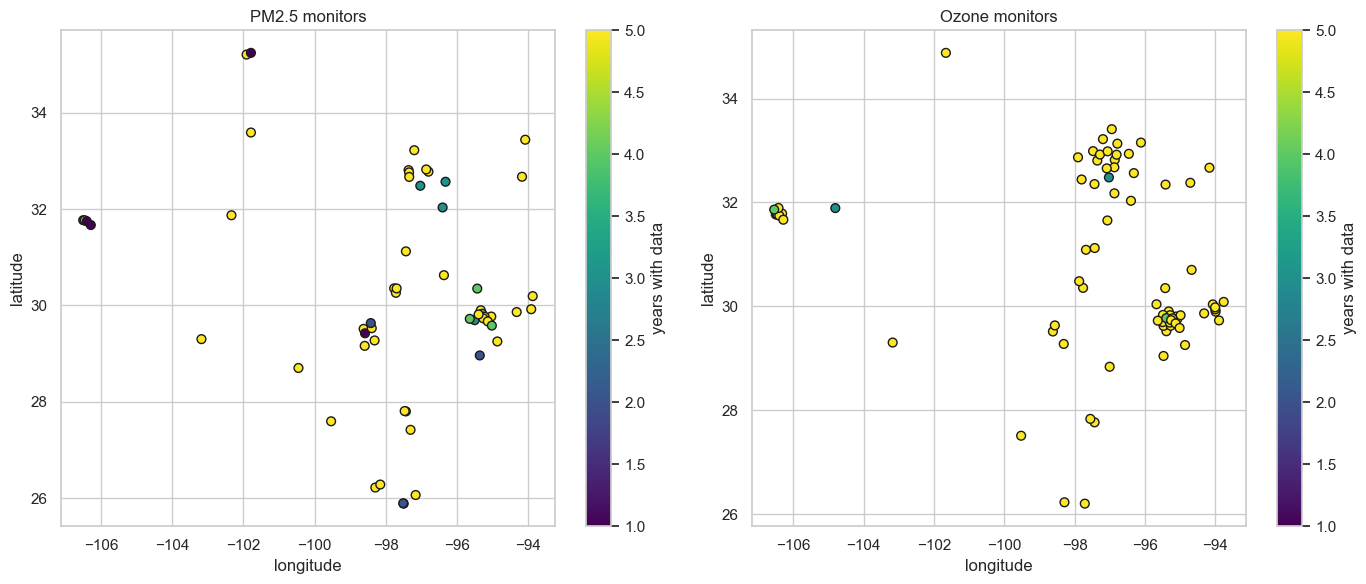

In [37]:
# where are the monitors? (color = number of years with data)
pm_sites = pm_used.groupby("site_id").agg(lat=("latitude", "first"), lon=("longitude", "first"), years=("year", "nunique"))
oz_sites = oz_used.groupby("site_id").agg(lat=("latitude", "first"), lon=("longitude", "first"), years=("year", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, sites, title in [(axes[0], pm_sites, "PM2.5 monitors"), (axes[1], oz_sites, "Ozone monitors")]:
    sc = ax.scatter(sites["lon"], sites["lat"], c=sites["years"], cmap="viridis", vmin=1, vmax=5, s=40, edgecolor="k")
    ax.set_title(title)
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    plt.colorbar(sc, ax=ax, label="years with data")
plt.tight_layout()
plt.show()

In [38]:
# monitors are concentrated in a few counties
top_counties = pd.DataFrame({
    "PM25_sites": pm_used.groupby("county_name")["site_id"].nunique(),
    "Ozone_sites": oz_used.groupby("county_name")["site_id"].nunique(),
}).fillna(0).astype(int).sort_values("Ozone_sites", ascending=False)
top_counties.head(10)

,PM25_sites,Ozone_sites
county_name,,
Harris,10,17
El Paso,4,7
Jefferson,2,6
Tarrant,3,5
Bexar,5,3
Dallas,2,3
Denton,1,2
Brazoria,1,2
Nueces,2,2


In [39]:
# each site keeps the same coordinates and name in every year?
print("PM2.5 sites with more than one lat/lon:", (pm.groupby("site_id")[["latitude", "longitude"]].nunique() > 1).any(axis=1).sum())
print("Ozone sites with more than one lat/lon:", (oz.groupby("site_id")[["latitude", "longitude"]].nunique() > 1).any(axis=1).sum())
print("Sites that measure both pollutants:", len(set(pm_sites.index) & set(oz_sites.index)))

PM2.5 sites with more than one lat/lon: 0
Ozone sites with more than one lat/lon: 0
Sites that measure both pollutants: 28


- Monitors are concentrated in big metro areas (Houston/Harris County, Dallas–Fort Worth, San Antonio, Austin, El Paso). West and rural Texas have few monitors.
- Each site's location and name stay the same across years.
- Only some sites measure **both** pollutants, so PM2.5 vs ozone comparisons at the same site will use fewer locations.

## 10. Unusual values

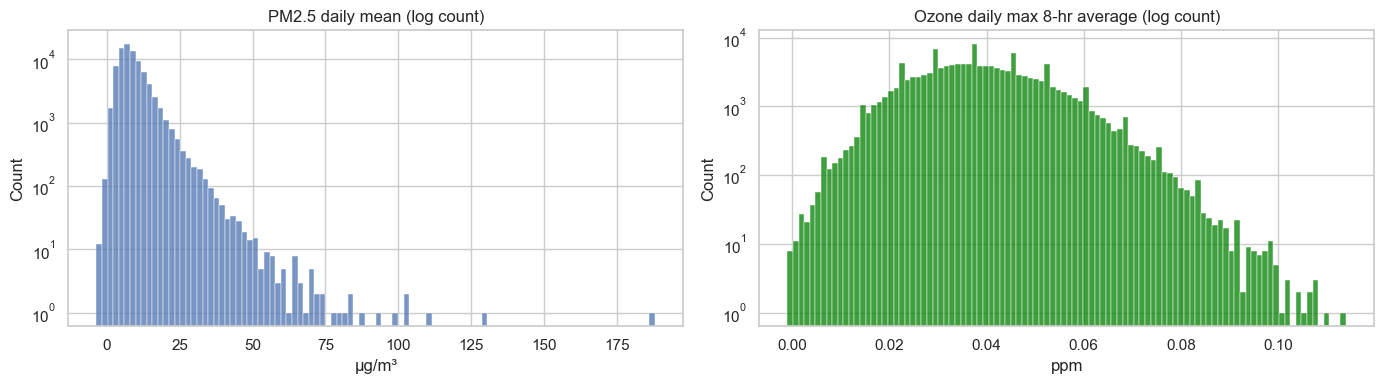

count    83863.000
mean         9.106
std          5.688
min         -3.600
25%          5.500
50%          7.900
75%         11.200
max        188.100
Name: arithmetic_mean, dtype: float64
count    129617.0000
mean          0.0389
std           0.0131
min          -0.0010
25%           0.0300
50%           0.0380
75%           0.0470
max           0.1140
Name: first_max_value, dtype: float64


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(pm_used["arithmetic_mean"], bins=100, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("PM2.5 daily mean (log count)")
axes[0].set_xlabel("µg/m³")
sns.histplot(oz_used["first_max_value"], bins=100, ax=axes[1], color="green")
axes[1].set_yscale("log")
axes[1].set_title("Ozone daily max 8-hr average (log count)")
axes[1].set_xlabel("ppm")
plt.tight_layout()
plt.show()

print(pm_used["arithmetic_mean"].describe().round(3))
print(oz_used["first_max_value"].describe().round(4))

### 10.1 Negative values

In [41]:
pm_neg = pm_used[pm_used["arithmetic_mean"] < 0]
oz_neg = oz_used[(oz_used["first_max_value"] < 0) | (oz_used["arithmetic_mean"] < 0)]
print("PM2.5 negative daily means:", len(pm_neg), "| smallest:", pm_neg["arithmetic_mean"].min())
print("Ozone negative values:", len(oz_neg))
pm_neg["arithmetic_mean"].value_counts().sort_index().head(10)

PM2.5 negative daily means: 88 | smallest: -3.6
Ozone negative values: 1


arithmetic_mean
-3.6    1
-2.7    2
-2.5    1
-2.4    3
-2.3    1
-2.1    1
-1.9    2
-1.7    1
-1.6    2
-1.5    1
Name: count, dtype: int64

In [42]:
oz_neg[["site_id", "date_local", "first_max_value", "arithmetic_mean", "observation_percent"]]

,site_id,date_local,first_max_value,arithmetic_mean,observation_percent
37882,48-201-0066,2021-02-10,-0.001,-0.001706,100.0


Small negative numbers happen when the real concentration is close to zero and the instrument has a little noise. EPA accepts readings down to about −10 µg/m³ for PM2.5. These are **valid data** and only a tiny fraction of rows.

### 10.2 Very high values

In [43]:
pm_used.nlargest(10, "arithmetic_mean")[["site_id", "local_site_name", "county_name", "date_local",
                                         "arithmetic_mean", "aqi", "event_type"]]

,site_id,local_site_name,county_name,date_local,arithmetic_mean,aqi,event_type
146672,48-203-0002,Karnack,Harrison,2024-04-05,188.1,263.0,Included
146670,48-203-0002,Karnack,Harrison,2024-04-04,129.1,205.0,Included
10571,48-201-0024,Houston Aldine,Harris,2020-01-01,110.6,190.0,None
140334,48-201-0046,Houston North Wayside,Harris,2024-01-01,103.1,184.0,None
6319,48-061-2004,Isla Blanca State Park Road,Cameron,2020-06-26,103.0,184.0,None
74262,48-203-0002,Karnack,Harrison,2022-01-21,98.1,181.0,Included
145792,48-201-1052,Houston North Loop,Harris,2024-01-01,94.0,178.0,None
16594,48-273-0314,National Seashore,Kleberg,2020-06-26,87.7,174.0,None
133821,48-061-2004,Isla Blanca State Park Road,Cameron,2024-05-10,83.4,171.0,None
133835,48-061-2004,Isla Blanca State Park Road,Cameron,2024-05-17,82.7,170.0,None


In [44]:
oz_used.nlargest(10, "first_max_value")[["site_id", "local_site_name", "county_name", "date_local",
                                         "first_max_value", "aqi", "event_type"]]

,site_id,local_site_name,county_name,date_local,first_max_value,aqi,event_type
49447,48-439-0075,Eagle Mountain Lake,Tarrant,2021-06-16,0.114,209,None
91233,48-201-1034,Houston East,Harris,2023-05-18,0.110,205,None
90153,48-201-0417,Houston Harvard Street,Harris,2023-05-18,0.108,203,None
91582,48-201-1035,Clinton,Harris,2023-05-18,0.108,203,None
127391,48-439-2003,Keller,Tarrant,2024-08-08,0.108,203,None
126674,48-439-0075,Eagle Mountain Lake,Tarrant,2024-08-08,0.107,202,None
115936,48-201-0417,Houston Harvard Street,Harris,2024-06-07,0.106,201,None
112454,48-201-0024,Houston Aldine,Harris,2024-08-21,0.105,200,None
90892,48-201-1017,Baytown Garth,Harris,2023-06-09,0.104,197,None
127050,48-439-1002,Fort Worth Northwest,Tarrant,2024-08-20,0.104,197,None


The highest values have real explanations:
- **January 1** in Houston → New Year's fireworks
- **June 26, 2020** along the coast (Isla Blanca, National Seashore) → the big Saharan dust storm
- **Karnack (April 2024)** → event-flagged by EPA (`event_type = Included`), likely smoke/fires

So these are real pollution events, **not errors**, and should be kept.

### 10.3 Ozone days with incomplete measurements
`observation_percent` tells us what share of the day's 8-hour averages were available. EPA treats a day as complete when it is at least 75%.

In [45]:
oz_used["completeness"] = pd.cut(oz_used["observation_percent"], bins=[0, 25, 50, 75, 99.9, 100],
                                 labels=["0-25%", "25-50%", "50-75%", "75-99%", "100%"])
print(oz_used["completeness"].value_counts().sort_index())
print("\nOzone analysis rows below 75% complete:", (oz_used["observation_percent"] < 75).sum())
print("PM2.5 analysis rows below 75% complete:", (pm_used["observation_percent"] < 75).sum())

completeness
0-25%        242
25-50%       469
50-75%      3178
75-99%      2265
100%      123463
Name: count, dtype: int64

Ozone analysis rows below 75% complete: 3889
PM2.5 analysis rows below 75% complete: 0


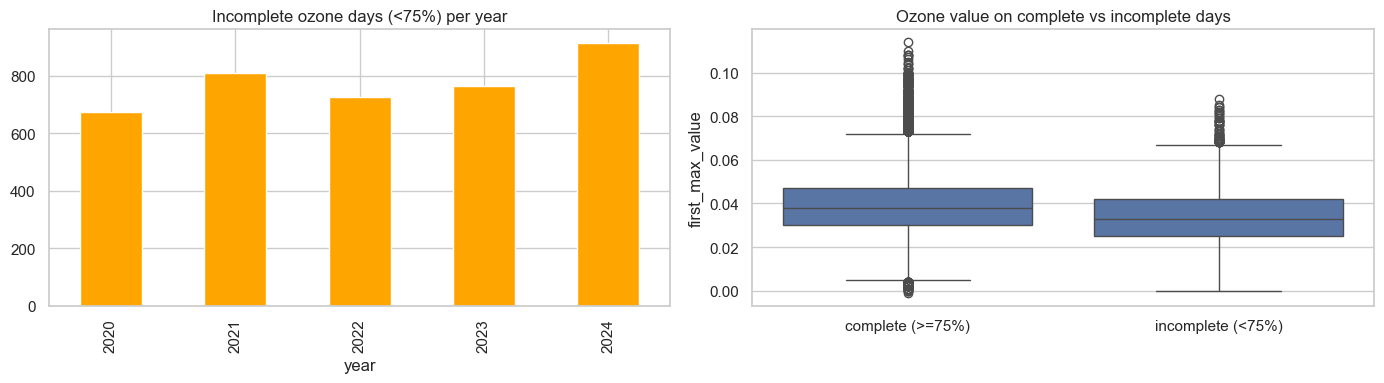

In [46]:
low = oz_used[oz_used["observation_percent"] < 75]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
low.groupby("year").size().plot(kind="bar", ax=axes[0], color="orange")
axes[0].set_title("Incomplete ozone days (<75%) per year")
sns.boxplot(x=oz_used["observation_percent"] < 75, y=oz_used["first_max_value"], ax=axes[1])
axes[1].set_xticks([0, 1], ["complete (>=75%)", "incomplete (<75%)"])
axes[1].set_xlabel("")
axes[1].set_title("Ozone value on complete vs incomplete days")
plt.tight_layout()
plt.show()

3,889 ozone rows (3%) are incomplete days. Their median is 0.033 ppm vs 0.038 ppm on complete days – they read **lower**, because the missing hours are often the afternoon when ozone peaks. Including them could make some sites look cleaner than they are.
(All PM2.5 analysis rows are already 100% complete because the 24-hour average only exists for complete days.)

## 11. Checking the merged PM2.5 + Ozone file
The merged file has **one row per site per day**, with PM2.5 and ozone side by side when both were measured at the same site.

In [47]:
merged = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_PM25_Ozone_SiteDay_Merged.csv")
print(merged.shape)
print("Duplicate site-days:", merged.duplicated(["site_id", "date_local"]).sum())
pd.crosstab(merged["year"], merged["match_status"], margins=True)

(170660, 16)
Duplicate site-days: 0


match_status,both_pollutants,ozone_only,pm25_only,All
year,,,,
2020,5242,20627,7308,33177
2021,6533,19975,7615,34123
2022,7725,17902,8346,33973
2023,7765,17894,8607,34266
2024,8352,17602,9167,35121
All,35617,94000,41043,170660


In [48]:
# does it contain every site-day from the combined files?
pm_site_days = pm_used[["site_id", "date_local"]].drop_duplicates()
oz_site_days = oz_used[["site_id", "date_local"]].drop_duplicates()
print("PM2.5 site-days in combined file:", len(pm_site_days), "| in merged file:", merged["pm25_daily_mean_ugm3"].notna().sum())
print("Ozone site-days in combined file:", len(oz_site_days), "| in merged file:", merged["ozone_mda8_ppm"].notna().sum())

# is the merged PM2.5 value the average of the monitors at that site-day?
check = pm_used.groupby(["site_id", "date_local"])["arithmetic_mean"].mean().reset_index()
check = check.merge(merged[["site_id", "date_local", "pm25_daily_mean_ugm3"]], on=["site_id", "date_local"])
print("Max difference vs. our own average:", (check["arithmetic_mean"] - check["pm25_daily_mean_ugm3"]).abs().max())

PM2.5 site-days in combined file: 76660 | in merged file: 76660
Ozone site-days in combined file: 129617 | in merged file: 129617
Max difference vs. our own average: 7.105427357601002e-15


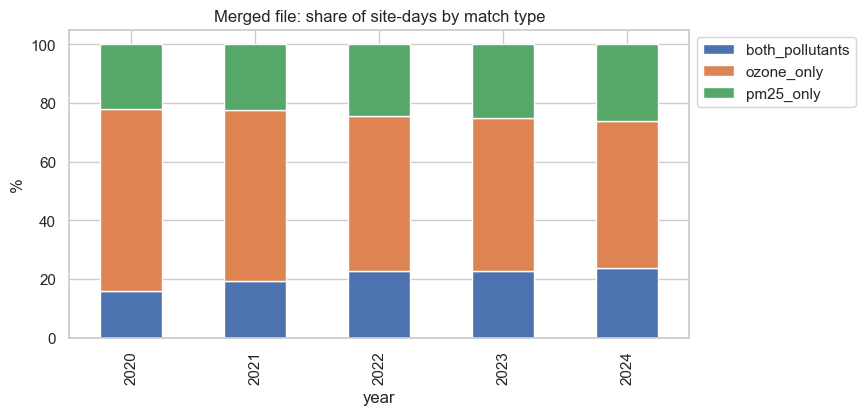

In [49]:
pd.crosstab(merged["year"], merged["match_status"], normalize="index").mul(100).round(1).plot(
    kind="bar", stacked=True, figsize=(8, 4))
plt.title("Merged file: share of site-days by match type")
plt.ylabel("%")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

- The merge is correct: one row per site-day, no site-days lost, PM2.5 values are the average of co-located monitors.
- It was an **outer join**, so most rows have only one pollutant (`ozone_only` / `pm25_only`). Only ~20% of site-days have both. This is expected because many sites only measure one pollutant – it's not lost data.
- The merged file includes ozone days that are <75% complete (Section 10.3).

## 12. Summary of findings

| # | Check | Result |
|---|-------|--------|
| 1 | Years & pollutants | PM2.5 and ozone, all 5 years (2020–2024), every month present |
| – | Loading gotcha | Must read CSVs with `keep_default_na=False, na_values=[""]` or EPA's `None` event type turns into NaN |
| 2 | Columns, types, units | Identical 29 EPA columns + 5 added; same types every year; one unit per pollutant (µg/m³, ppm) |
| 3 | Missing values | No missing measurements, dates or coordinates in analysis rows. Gaps are only in names/metro area and in the flagged `1 HOUR` rows |
| 4 | Duplicates | No duplicate rows. PM2.5 has 7,047 site-days with 2+ co-located monitors (real, not duplicates) |
| 5 | Previous filtering | Correct. 0 Texas rows removed; rows were **flagged**, not deleted |
| 6 | Flags | `1 HOUR` PM2.5 rows (80,356) are copies of the daily average → correctly flagged. 16 ozone "Excluded" event rows correctly flagged |
| 7 | Station coverage | PM2.5 sites grow from 43 to 54; ozone stays 73–76. Some sites start/stop mid-period; many FRM sites sample every 3rd/6th day |
| 8 | Unusual values | 88 small negative PM2.5 values and a few negative ozone values (instrument noise near zero); extreme highs are real events |
| 9 | Incomplete days | 3,889 ozone analysis rows are <75% complete and tend to read low |
| 10 | Merged file | Correct, but outer join → most rows have only one pollutant |
| 11 | Info lost? | Nothing was lost. 2,015 incomplete PM2.5 monitor-days exist only as flagged `1 HOUR` rows (kept in the file) |

**Next step:** review the proposed cleaning plan before any changes are made.